# Swiss Ecological Scarcity 2021 (UBP) with Edges

This annotated example demonstrates the bundled Swiss Ecological Scarcity 2021 method (version 1.06), also known as the eco-factor or UBP method. It calculates the total and all 20 additive indicators, checks exchange matching, explains which indicators are geographically regionalized, verifies the technosphere-based Noise implementation, and creates a publication-ready figure.

The example uses an exact ecoinvent cutoff 3.11 activity rather than a random dataset so that the calculation is reproducible. The selected lorry-transport market has both elementary-flow impacts and a direct transport-service exchange characterized by the Noise indicator.

## Requirements and data boundary

You need Edges and a local licensed ecoinvent 3.11 cutoff project. Change `PROJECT` and `DATABASE` below if your local names differ. The notebook reports only the selected activity metadata, aggregate scores, matching counts, and a short contribution table; it does not export ecoinvent inventory data.

In [1]:
import gc
import json
from pathlib import Path

import bw2data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

import edges
from edges import EdgeLCIA, get_available_methods

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

## Select the project and an exact functional unit

The functional unit is **1 ton kilometer** supplied by the Swiss market for 28-tonne FAME lorry transport. Matching on name, reference product, location, and unit must return exactly one activity. This avoids the ambiguity of selecting a random activity or matching on a partial name.

In [2]:
PROJECT = "ecoinvent-3.11-cutoff"
DATABASE = "ecoinvent-3.11-cutoff"
ACTIVITY_NAME = (
    "market for transport, freight, lorry 28 metric ton, "
    "fatty acid methyl ester 100%"
)
REFERENCE_PRODUCT = ACTIVITY_NAME.removeprefix("market for ")
LOCATION = "CH"
UNIT = "ton kilometer"
AMOUNT = 1.0

project_names = {project.name for project in bw2data.projects}
if PROJECT not in project_names:
    raise ValueError(f"Brightway project {PROJECT!r} is not installed")
bw2data.projects.set_current(PROJECT, writable=False, update=False)
if DATABASE not in bw2data.databases:
    raise ValueError(f"Database {DATABASE!r} is not present in {PROJECT!r}")

matches = [
    activity
    for activity in bw2data.Database(DATABASE)
    if activity.get("name") == ACTIVITY_NAME
    and activity.get("reference product") == REFERENCE_PRODUCT
    and activity.get("location") == LOCATION
    and activity.get("unit") == UNIT
]
if len(matches) != 1:
    raise ValueError(f"Expected one exact functional-unit activity; found {len(matches)}")
activity = matches[0]
functional_unit = {activity: AMOUNT}

pd.DataFrame(
    [{
        "project": PROJECT,
        "database": DATABASE,
        "activity": activity.get("name"),
        "reference product": activity.get("reference product"),
        "location": activity.get("location"),
        "unit": activity.get("unit"),
        "amount": AMOUNT,
        "activity key": str(activity.key),
    }]
)

,project,database,activity,reference product,location,unit,amount,activity key
0,ecoinvent-3.11-cutoff,ecoinvent-3.11-cutoff,"market for transport, freight, lorry 28 metric ton, fatty acid methyl ester 100%","transport, freight, lorry 28 metric ton, fatty acid methyl ester 100%",CH,ton kilometer,1.0,"('ecoinvent-3.11-cutoff', 'c0871401a9f4fdcba56beef25d28ed4b')"


## Inspect the bundled methods

Edges distributes 21 UBP method files: one total and 20 separately callable indicators. Every result is expressed in eco-points (`UBP`), and the total is the exact sum of the category scores because the source weighting set assigns a weight of one to each category.

In [3]:
UBP_METHODS = sorted(
    [method for method in get_available_methods() if method[0] == "Ecological Scarcity 2021"],
    key=lambda method: (method[1] != "total", method[1]),
)
assert len(UBP_METHODS) == 21
pd.DataFrame(UBP_METHODS, columns=["method", "indicator", "unit"])

,method,indicator,unit
0,Ecological Scarcity 2021,total,UBP
1,Ecological Scarcity 2021,Biotic resources,UBP
2,Ecological Scarcity 2021,Carcinogenic substances into air,UBP
3,Ecological Scarcity 2021,Energy resources,UBP
4,Ecological Scarcity 2021,Global warming,UBP
5,Ecological Scarcity 2021,Heavy metals into air,UBP
6,Ecological Scarcity 2021,Heavy metals into soil,UBP
7,Ecological Scarcity 2021,Heavy metals into water,UBP
8,Ecological Scarcity 2021,Land use,UBP
9,Ecological Scarcity 2021,Main air pollutants and particulates,UBP


## Calculate the mixed-matrix total

The usual Edges workflow is unchanged. The UBP total is a mixed method: environmental interventions are characterized on biosphere-to-technosphere edges, while Noise is characterized on technosphere-to-technosphere transport-service edges. `score_by_matrix` makes this split explicit.

In [4]:
TOTAL_METHOD = ("Ecological Scarcity 2021", "total", "UBP")

total_lca = EdgeLCIA(demand=functional_unit, method=TOTAL_METHOD)
total_lca.lci()
total_lca.apply_strategies()
total_lca.evaluate_cfs()
total_lca.lcia()

matrix_scores = pd.DataFrame(
    [
        {"component": matrix, "score [UBP]": float(score)}
        for matrix, score in total_lca.score_by_matrix.items()
    ]
)
matrix_scores.loc[len(matrix_scores)] = {"component": "total", "score [UBP]": float(total_lca.score)}
matrix_scores

Finding direct matches        [1/5]


Resolving aggregate locations [2/5]


Resolving dynamic locations   [3/5]


Resolving contained locations [4/5]


Resolving global locations    [5/5]


,component,score [UBP]
0,biosphere,918.980260
1,technosphere,32.442957
2,total,951.423217


The following table records how many unique inventory edges each matching strategy characterized. Direct matching is attempted first; geographic fallback strategies are relevant only when a location-conditioned rule needs them. A zero in a later stage means the assessed supply chain did not require that fallback—not that the strategy is unavailable.

In [5]:
pd.DataFrame(total_lca.strategy_match_counts)

,strategy,new_biosphere_matches,new_technosphere_matches,cumulative_matches
0,map_exchanges,200292,183,200475
1,map_aggregate_locations,0,0,200475
2,map_dynamic_locations,0,0,200475
3,map_contained_locations,0,0,200475
4,map_remaining_locations_to_global,0,0,200475


## Which indicators are regionalized?

The method is **partly regionalized**. Only Land use, Main air pollutants and particulates, Water pollutants, and Water resources (net balance) contain explicit consumer-location conditions. The other 16 indicators use geography-independent eco-factors. Noise varies by transport family and vehicle class, but not by consumer location.

Some rules inside a regionalized indicator remain unconditioned: they are general factors or defaults alongside the geographic rules. The counts below are read directly from the installed JSON method files.

In [6]:
method_data_dir = Path(edges.__file__).resolve().parent / "data"
regionalization_records = []
for method in UBP_METHODS:
    if method[1] == "total":
        continue
    path = method_data_dir / f"Ecological Scarcity 2021_{method[1]}_UBP.json"
    payload = json.loads(path.read_text(encoding="utf-8"))
    rules = payload["exchanges"]
    location_rules = sum(
        rule.get("consumer", {}).get("location") is not None for rule in rules
    )
    regionalization_records.append(
        {
            "indicator": method[1],
            "rules": len(rules),
            "location-conditioned rules": location_rules,
            "geographic mode": "regionalized" if location_rules else "geography-independent",
        }
    )
regionalization = pd.DataFrame(regionalization_records).sort_values(
    ["geographic mode", "indicator"], ascending=[False, True]
).reset_index(drop=True)
regionalization

,indicator,rules,location-conditioned rules,geographic mode
0,Land use,1040,994,regionalized
1,Main air pollutants and particulates,10738,10366,regionalized
2,Water pollutants,7673,7515,regionalized
3,"Water resources, net balance",6956,6942,regionalized
4,Biotic resources,2,0,geography-independent
5,Carcinogenic substances into air,62,0,geography-independent
6,Energy resources,13,0,geography-independent
7,Global warming,59,0,geography-independent
8,Heavy metals into air,41,0,geography-independent
9,Heavy metals into soil,35,0,geography-independent


## Calculate all 20 category scores

Each category can be run independently by changing the second item in the method tuple. The loop deliberately uses the public Edges workflow for every indicator. It can take several minutes because each category performs its own exchange-matching pass. The final assertion is a useful integrity check: the sum of the 20 category scores must reproduce the mixed total.

In [7]:
category_results = []
noise_lca = None
category_methods = [method for method in UBP_METHODS if method[1] != "total"]

for index, method in enumerate(category_methods, start=1):
    print(f"[{index:02d}/{len(category_methods)}] {method[1]}")
    category_lca = EdgeLCIA(demand=functional_unit, method=method)
    category_lca.lci()
    category_lca.apply_strategies()
    category_lca.evaluate_cfs()
    category_lca.lcia()
    category_results.append({"indicator": method[1], "score [UBP]": float(category_lca.score)})
    if method[1] == "Noise":
        noise_lca = category_lca
    else:
        del category_lca
        gc.collect()

category_scores = pd.DataFrame(category_results).merge(
    regionalization[["indicator", "geographic mode"]], on="indicator", validate="one_to_one"
)
category_sum = category_scores["score [UBP]"].sum()
assert np.isclose(category_sum, total_lca.score, rtol=1e-10, atol=1e-8)
assert np.isclose(
    category_scores.loc[category_scores["indicator"] == "Noise", "score [UBP]"].iloc[0],
    total_lca.score_by_matrix["technosphere"],
    rtol=1e-10,
    atol=1e-8,
)
category_scores.sort_values("score [UBP]", ascending=False).reset_index(drop=True)

[01/20] Biotic resources


Finding direct matches        [1/5]


Resolving aggregate locations [2/5]


Resolving dynamic locations   [3/5]


Resolving contained locations [4/5]


...

Resolving aggregate locations [2/5]


Resolving dynamic locations   [3/5]


Resolving contained locations [4/5]


Resolving global locations    [5/5]


,indicator,score [UBP],geographic mode
0,Water pollutants,2.508875e+02,regionalized
1,Pesticides into soil,2.005905e+02,geography-independent
2,Land use,1.524228e+02,regionalized
3,Global warming,1.237974e+02,geography-independent
4,Main air pollutants and particulates,1.102656e+02,regionalized
5,Noise,3.244296e+01,geography-independent
6,Heavy metals into soil,2.637126e+01,geography-independent
7,Energy resources,2.113346e+01,geography-independent
8,Mineral resources,9.396568e+00,geography-independent
9,Heavy metals into air,9.013832e+00,geography-independent


## Figure: category contributions to the UBP total

Because all category weights are one and all scores share the UBP unit, their absolute contributions can be compared and summed directly. Blue bars mark indicators with geographic rules; grey bars mark geography-independent indicators. The symmetric logarithmic axis keeps small and potentially negative contributions visible without changing their sign.

Saved figure to figure_ecological_scarcity_2021_ubp_lorry.png


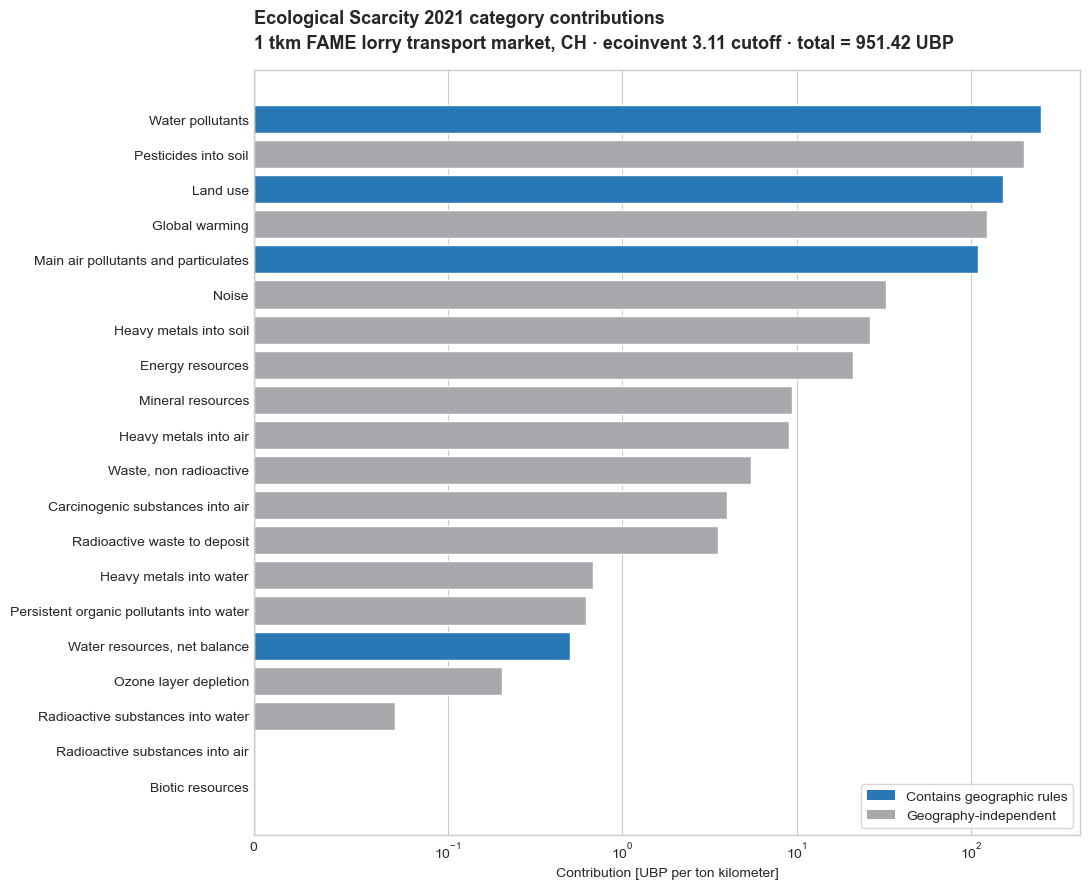

In [8]:
plot_data = category_scores.sort_values("score [UBP]", ascending=True).copy()
colors = plot_data["geographic mode"].map(
    {"regionalized": "#2878B5", "geography-independent": "#A7A9AC"}
)

fig, ax = plt.subplots(figsize=(11, 9))
bars = ax.barh(plot_data["indicator"], plot_data["score [UBP]"], color=colors, edgecolor="white")
ax.set_xscale("symlog", linthresh=0.1)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Contribution [UBP per ton kilometer]")
ax.set_ylabel("")
ax.set_title(
    "Ecological Scarcity 2021 category contributions\n"
    f"1 tkm FAME lorry transport market, CH · ecoinvent 3.11 cutoff · total = {total_lca.score:,.2f} UBP",
    loc="left",
    weight="bold",
    fontsize=13,
    pad=16,
    linespacing=1.5,
)
ax.legend(
    handles=[
        Patch(facecolor="#2878B5", label="Contains geographic rules"),
        Patch(facecolor="#A7A9AC", label="Geography-independent"),
    ],
    loc="lower right", frameon=True,
)
ax.grid(axis="y", visible=False)
fig.tight_layout()

output_dir = Path("examples/various examples")
if not output_dir.is_dir():
    output_dir = Path.cwd()
figure_path = output_dir / "figure_ecological_scarcity_2021_ubp_lorry.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight", facecolor="white")
print(f"Saved figure to {figure_path.name}")
plt.show()

## Verify the direct Noise factor

SimaPro's lorry Noise factor is 180 UBP per vehicle-kilometre. For the ecoinvent 28-tonne service, Edges converts this using the reviewed 5.79-tonne average payload, giving `180 / 5.79 = 31.088... UBP/tkm`. The matched-only Noise table is small enough to inspect directly. Market and market-group providers are excluded from the method rules to avoid characterizing the same transport service twice.

In [9]:
noise_table = noise_lca.generate_cf_table(include_unmatched=False)
direct_noise = noise_table.loc[
    (noise_table["supplier name"] == REFERENCE_PRODUCT)
    & (noise_table["consumer name"] == ACTIVITY_NAME)
]
assert len(direct_noise) == 1
assert np.isclose(direct_noise["CF"].iloc[0], 180 / 5.79, rtol=1e-12)
direct_noise[
    ["supplier name", "consumer name", "amount", "CF", "impact"]
]

,supplier name,consumer name,amount,CF,impact
72,"transport, freight, lorry 28 metric ton, fatty acid methyl ester 100%","market for transport, freight, lorry 28 metric ton, fatty acid methyl ester 100%",1.0,31.088083,31.088083


## Inspect exchange matching and contributions

`include_unmatched=True` returns the complete assessed inventory edge set. An unmatched edge is not automatically an error: many elementary flows and nearly all technosphere exchanges are outside the scope of this method. The useful validation question is whether an exchange eligible for one of the method's rules was missed; the repository's dedicated cross-version audit performs that exhaustive check. Here we reconcile the matched table impacts with the calculated matrix scores and display only the twelve largest absolute contributions.

In [10]:
total_cf = total_lca.generate_cf_table(include_unmatched=True)
matching_summary = (
    total_cf.assign(matched=total_cf["CF"].notna())
    .groupby("supplier matrix", as_index=False)
    .agg(
        inventory_edges=("matched", "size"),
        matched_edges=("matched", "sum"),
        matched_impact_UBP=("impact", lambda values: values.dropna().sum()),
    )
)
matching_summary["unmatched_edges"] = (
    matching_summary["inventory_edges"] - matching_summary["matched_edges"]
)
for _, row in matching_summary.iterrows():
    assert np.isclose(
        row["matched_impact_UBP"],
        total_lca.score_by_matrix[row["supplier matrix"]],
        rtol=1e-10,
        atol=1e-8,
    )
matching_summary

,supplier matrix,inventory_edges,matched_edges,matched_impact_UBP,unmatched_edges
0,biosphere,401594,200292,918.980260,201302
1,technosphere,164053,183,32.442957,163870


In [11]:
top_contributions = (
    total_cf.loc[total_cf["CF"].notna()]
    .assign(abs_impact=lambda frame: frame["impact"].abs())
    .nlargest(12, "abs_impact")
)
top_contributions[
    [
        "supplier matrix",
        "supplier name",
        "consumer name",
        "consumer location",
        "amount",
        "CF",
        "impact",
    ]
].reset_index(drop=True)

,supplier matrix,supplier name,consumer name,consumer location,amount,CF,impact
0,biosphere,Nitrate,"rape seed production, Swiss integrated production, intensive",CH,0.005815,27000.0,157.015747
1,biosphere,"Occupation, annual crop, non-irrigated, intensive","rape seed production, Swiss integrated production, intensive",CH,0.188419,520.0,97.978087
2,biosphere,Nitrate,"rape seed production, Swiss integrated production, extensive",CH,0.002703,27000.0,72.985356
3,biosphere,Tebutam,"rape seed production, Swiss integrated production, intensive",CH,0.000023,2800000.0,63.697101
4,biosphere,Trifluralin,"rape seed production, Swiss integrated production, extensive",CH,0.000004,12000000.0,52.707904
5,biosphere,Tebutam,"rape seed production, Swiss integrated production, extensive",CH,0.000018,2800000.0,50.264354
6,biosphere,Water,"electricity production, hydro, run-of-river",FR,0.254848,-190.0,-48.421041
7,biosphere,"Water, turbine use, unspecified natural origin","electricity production, hydro, run-of-river",FR,0.254848,190.0,48.421041
8,biosphere,Water,"electricity production, hydro, run-of-river",RoW,0.042517,-990.0,-42.091437
9,biosphere,"Water, turbine use, unspecified natural origin","electricity production, hydro, run-of-river",RoW,0.042517,990.0,42.091437


## Interpretation and reproducibility

The category chart is a contribution profile for this functional unit, not a general ranking of the indicators. Results will change with the activity, location, database version, and system model. The four blue indicators may also change through Edges' geographic fallback logic when their consumer locations differ.

For release validation, `dev/UBP/build_ubp_methods.py check` verifies source identity, complete source-row disposition, rule uniqueness, and ecoinvent 3.10–3.12 supplier reachability. `dev/UBP/run_ubp_matching_audit.py` performs exact end-to-end calculations and proves that every directly eligible elementary-flow and Noise exchange is matched. The licensed SimaPro source and detailed ecoinvent CF tables are intentionally excluded from Git.